# Funnel onboarding super-app: ELT di PostgreSQL, analisis di Python

Notebook ini mengerjakan seluruh case funnel onboarding (modul SQL-03) dalam satu alur:

1. **Load**: memuat `data/user_events.csv` apa adanya ke tabel `bronze.user_events` di PostgreSQL. Data mentah ini dari modul dan **tidak disertakan di repositori**; letakkan sendiri di folder `data/` sebelum menjalankan notebook. Kalau database sudah berisi data, langkah ini dilewati.
2. **Transform**: membangun lapisan `silver` (data bersih, keanggotaan tahap) dan `gold` (angka siap analisis) dengan skrip SQL di folder `sql/`.
3. **Analisis**: mengambil hasil dari database, menguji statistik, menggambar grafik, dan mengekspor empat berkas keluaran modul.

Semua angka dihitung oleh SQL di database; Python hanya mengambil hasilnya, mengujinya, dan menggambarnya.

**Pertanyaan bisnis.** Pak Fajar (VP of Product) memegang anggaran akuisisi Rp 2 miliar per bulan dan satu antrean kerja perbaikan. Yang ia butuhkan: di tahap mana pengguna onboarding hilang.

**Prasyarat.** PostgreSQL terpasang, database `funnel_onboarding` sudah dibuat (kosong pun boleh), dan `user_events.csv` dari modul diletakkan di folder `data/`. Langkah singkatnya ada di README.

![Alur pengerjaan](grafik/alur_pengerjaan.png)

| Bagian | Isi | Berkas keluaran modul |
|---|---|---|
| 0 | Koneksi ke PostgreSQL | |
| ELT | Load CSV ke bronze, Transform ke silver dan gold, validasi lintas lapisan | |
| 1 | Bronze: data mentah dan kotorannya | |
| 2 | Silver: rekonsiliasi pembersihan | berkas 1 |
| 3 | Gold: funnel dan konversi | berkas 2 |
| 4 | Gold: pecahan platform dan kota | berkas 3 |
| 5 | Gold: jarak waktu antar-tahap | |
| 6 | Lima pemeriksaan validasi | berkas 4 |
| 7 | Uji ketahanan dan uji statistik | |
| 8 | Sembilan grafik | `grafik/` |
| 9 | Ekspor berkas dan gerbang angka | `berkas/` |
| 10 | Temuan dan rekomendasi | |

## 0. Koneksi ke PostgreSQL

In [1]:
# Sekali saja di Command Prompt:  pip install jupyterlab pandas matplotlib scipy sqlalchemy psycopg2-binary
import os, getpass
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

pd.set_option("display.width", 160)

# Password tidak ditulis di notebook. Isi lewat variabel lingkungan PGPASSWORD,
# atau ketik saat diminta (tidak tersimpan di berkas).
PG_PASSWORD = os.environ.get("PGPASSWORD") or getpass.getpass("Password PostgreSQL untuk user postgres: ")
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ.get("PGUSER", "postgres"),
    password=PG_PASSWORD,
    host=os.environ.get("PGHOST", "localhost"),
    port=int(os.environ.get("PGPORT", "5432")),
    database=os.environ.get("PGDATABASE", "funnel_onboarding"),
))

def q(sql: str) -> pd.DataFrame:
    # Jalankan SQL di PostgreSQL. Kolom NUMERIC (hasil ROUND) diubah ke float supaya bisa dihitung di pandas.
    with engine.connect() as conn:
        df = pd.read_sql(text(sql), conn)
    for c in df.columns:
        if df[c].map(lambda v: isinstance(v, Decimal)).any():
            df[c] = df[c].astype(float)
    return df

def angka_id(x, d=0):
    # Format Indonesia: titik ribuan, koma desimal.
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "–"
    s = f"{x:,.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

def bulat(x, d=2):
    # Pembulatan setengah ke atas, sama dengan ROUND di PostgreSQL.
    return float(Decimal(str(x)).quantize(Decimal(1).scaleb(-d), rounding=ROUND_HALF_UP))

def tampil(df, desimal=2):
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: angka_id(v, desimal))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(lambda v: angka_id(v, 0) if pd.notna(v) else "–")
    return out

os.makedirs("berkas", exist_ok=True)
os.makedirs("grafik", exist_ok=True)
TANGGAL = "2026-10-08"
q("SELECT current_database() AS database, version() AS versi")

,database,versi
0,funnel_onboarding,PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04....


## ELT: Load dan Transform

Bagian ini aman dijalankan berulang kali:

- **Load** hanya dikerjakan kalau `bronze.user_events` belum ada atau masih kosong. Kalau sudah berisi 80.000 baris, langkah ini dilewati, jadi data tidak pernah dobel. Kalau isinya jumlah lain, notebook berhenti dan meminta Anda memeriksanya, tanpa menghapus apa pun.
- **Transform** menjalankan `sql/02_silver.sql` dan `sql/03_gold.sql`. Keduanya memakai `CREATE OR REPLACE VIEW`, jadi menjalankan ulang hanya mengganti definisi view.
- Setiap skrip diakhiri tabel gerbang (ukuran, nilai, harapan, status) yang ditampilkan di bawah sebagai bukti.

In [2]:
def jalankan_skrip(path):
    # Jalankan satu berkas SQL utuh; kembalikan hasil pernyataan terakhirnya (tabel gerbang) bila ada.
    sql = open(path, encoding="utf-8").read()
    raw = engine.raw_connection()
    try:
        cur = raw.cursor()
        cur.execute(sql)
        hasil = pd.DataFrame(cur.fetchall(), columns=[d[0] for d in cur.description]) if cur.description else None
        raw.commit()
    finally:
        raw.close()
    if hasil is not None:
        for c in hasil.columns:
            if hasil[c].map(lambda v: isinstance(v, Decimal)).any():
                hasil[c] = hasil[c].astype(float)
    return hasil

def baris_bronze():
    ada = q("SELECT to_regclass('bronze.user_events') IS NOT NULL AS ada").ada[0]
    return int(q("SELECT COUNT(*) AS n FROM bronze.user_events").n[0]) if ada else None

# ---------- LOAD ----------
n_bronze = baris_bronze()
if n_bronze in (None, 0):
    if not os.path.exists("data/user_events.csv"):
        raise FileNotFoundError("data/user_events.csv belum ada. Data mentah tidak disertakan di repositori: "
                                "salin berkas user_events.csv dari modul ke folder data/, lalu jalankan ulang sel ini.")
    jalankan_skrip("sql/01_bronze.sql")                      # skema bronze/silver/gold + tabel kosong
    raw = engine.raw_connection()
    try:
        with open("data/user_events.csv", encoding="utf-8") as f:
            raw.cursor().copy_expert("COPY bronze.user_events FROM STDIN WITH (FORMAT csv, HEADER true)", f)
        raw.commit()
    finally:
        raw.close()
    print(f"Load selesai: {angka_id(baris_bronze())} baris dimuat ke bronze.user_events")
elif n_bronze == 80000:
    print("bronze.user_events sudah berisi 80.000 baris; Load dilewati supaya data tidak dobel")
else:
    raise RuntimeError(f"bronze.user_events berisi {n_bronze} baris, bukan 80.000. Periksa impor sebelumnya "
                       "(kemungkinan CSV terimpor dua kali). Kosongkan dengan TRUNCATE bronze.user_events; lalu jalankan ulang.")

bronze.user_events sudah berisi 80.000 baris; Load dilewati supaya data tidak dobel


In [3]:
# ---------- TRANSFORM ----------
gerbang_silver = jalankan_skrip("sql/02_silver.sql")
gerbang_gold = jalankan_skrip("sql/03_gold.sql")
assert (gerbang_silver.status == "cocok").all() and (gerbang_gold.status == "cocok").all(), "ada gerbang yang TIDAK COCOK"
print(f"Gerbang silver: {(gerbang_silver.status == 'cocok').sum()} dari {len(gerbang_silver)} cocok")
gerbang_silver

Gerbang silver: 8 dari 8 cocok


,ukuran,nilai,harapan,status
0,baris bronze,80000,80000,cocok
1,pengguna bronze,20000,20000,cocok
2,baris bersih (clean_events),76204,76204,cocok
3,pengguna bersih (clean_events),20000,20000,cocok
4,baris tahap funnel (stage_assignment),52582,52582,cocok
5,keanggotaan tahap (user_stages),52582,52582,cocok
6,pengguna funnel (user_stages),19994,19994,cocok
7,pengguna dengan dua baris di tahap yang sama,0,0,cocok


In [4]:
print(f"Gerbang gold: {(gerbang_gold.status == 'cocok').sum()} dari {len(gerbang_gold)} cocok")
gerbang_gold

Gerbang gold: 12 dari 12 cocok


,ukuran,nilai,harapan,status
0,pengguna tahap 1 Visit,19946.00,19946.00,cocok
1,pengguna tahap 2 SignUp,14874.00,14874.00,cocok
2,pengguna tahap 3 VerifyPhone,8144.00,8144.00,cocok
3,pengguna tahap 4 FirstOrder,5652.00,5652.00,cocok
4,pengguna tahap 5 SecondOrder,3966.00,3966.00,cocok
5,konversi SignUp ke VerifyPhone (%),54.75,54.75,cocok
6,berhenti di verifikasi (%),45.25,45.25,cocok
7,tahap yang jumlah platformnya tidak sama denga...,0.00,0.00,cocok
8,transisi bertetangga diperiksa,32477.00,32477.00,cocok
9,transisi bertetangga mundur,35.00,35.00,cocok


In [5]:
# ---------- VALIDASI LINTAS LAPISAN ----------
validasi_lapisan = jalankan_skrip("sql/04_validasi.sql")
assert (validasi_lapisan.status == "cocok").all(), "ada gerbang lintas lapisan yang TIDAK COCOK"
os.makedirs("bukti", exist_ok=True)
gerbang_silver.to_csv("bukti/gerbang_silver.csv", index=False)
gerbang_gold.to_csv("bukti/gerbang_gold.csv", index=False)
validasi_lapisan.to_csv("bukti/validasi.csv", index=False)
print(f"Validasi lintas lapisan: {(validasi_lapisan.status == 'cocok').sum()} dari {len(validasi_lapisan)} cocok; "
      "ketiga tabel gerbang disimpan di bukti/")
validasi_lapisan

Validasi lintas lapisan: 12 dari 12 cocok; ketiga tabel gerbang disimpan di bukti/


,ukuran,nilai,harapan,status
0,baris bronze,80000,80000,cocok
1,pengguna bronze,20000,20000,cocok
2,baris silver bersih,76204,76204,cocok
3,pengguna silver,20000,20000,cocok
4,keanggotaan tahap,52582,52582,cocok
5,tahap 1 Visit,19946,19946,cocok
6,tahap 2 SignUp,14874,14874,cocok
7,tahap 3 VerifyPhone,8144,8144,cocok
8,tahap 4 FirstOrder,5652,5652,cocok
9,tahap 5 SecondOrder,3966,3966,cocok


In [6]:
# Isi database sesudah ELT: satu tabel di bronze, view di silver dan gold
q('''
SELECT table_schema AS lapisan, table_name AS nama, table_type AS jenis
FROM information_schema.tables
WHERE table_schema IN ('bronze', 'silver', 'gold')
ORDER BY CASE table_schema WHEN 'bronze' THEN 1 WHEN 'silver' THEN 2 ELSE 3 END, table_name
''')

,lapisan,nama,jenis
0,bronze,user_events,BASE TABLE
1,silver,clean_events,VIEW
2,silver,stage_assignment,VIEW
3,silver,user_stages,VIEW
4,gold,conversion_rates,VIEW
5,gold,dim_tahap,VIEW
6,gold,fact_keanggotaan,VIEW
7,gold,fact_transisi,VIEW
8,gold,funnel_counts,VIEW
9,gold,platform_split,VIEW


## 1. Bronze: data mentah dan kotorannya

Bronze menyimpan CSV apa adanya. Di sini kotorannya hanya **dihitung**, tidak dibuang.

In [7]:
bronze = q('''
SELECT
    COUNT(*)                                                                    AS baris,
    COUNT(DISTINCT user_id)                                                     AS pengguna,
    MIN(event_timestamp)                                                        AS stempel_awal,
    MAX(event_timestamp)                                                        AS stempel_akhir,
    COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT user_id, event_name, event_timestamp, platform, city
                                      FROM bronze.user_events) d)              AS baris_kembar,
    COUNT(*) FILTER (WHERE event_name IS NULL OR TRIM(event_name) = '')         AS nama_kosong,
    COUNT(*) FILTER (WHERE event_timestamp > TIMESTAMP '2026-03-31 23:59:59')   AS stempel_masa_depan
FROM bronze.user_events
''')
tampil(bronze)

,baris,pengguna,stempel_awal,stempel_akhir,baris_kembar,nama_kosong,stempel_masa_depan
0,80.000,20.000,2025-01-01 00:11:00,2027-05-05 16:00:00,3.150,500,146


In [8]:
# Daftar nama peristiwa, dibaca dengan mata: dicari dua nama yang tampak seperti hal yang sama
tampil(q("SELECT event_name, COUNT(*) AS baris FROM bronze.user_events GROUP BY event_name ORDER BY baris DESC"))

,event_name,baris
0,Visit,20.808
1,SignUp,15.529
2,VerifyPhone,8.474
3,FirstOrder,5.913
4,BrowseCategory,4.973
5,OpenApp,4.935
6,ViewPromo,4.919
7,AddToCart,4.906
8,SearchProduct,4.901
9,SecondOrder,4.142


**Bacaan.** 80.000 baris dari 20.000 pengguna. Kotorannya tiga jenis: 3.150 baris kembar, 500 nama kosong, dan 146 stempel sesudah akhir periode (stempel akhir sampai 2027). Sepuluh nama peristiwa ditulis seragam; lima di antaranya tahap funnel.

## 2. Silver: rekonsiliasi pembersihan (berkas 1)

Tiap tahap pembuangan dicatat angkanya, dengan porsi terhadap data mentah supaya bisa dijumlahkan.

In [9]:
c = q('''
WITH deduped AS (
    SELECT MIN(event_id) AS event_id, user_id, event_name, event_timestamp, platform, city
    FROM bronze.user_events
    GROUP BY user_id, event_name, event_timestamp, platform, city),
named AS (SELECT * FROM deduped WHERE event_name IS NOT NULL AND TRIM(event_name) <> '')
SELECT (SELECT COUNT(*) FROM bronze.user_events)               AS mentah,
       (SELECT COUNT(*) FROM deduped)                          AS sesudah_kembar,
       (SELECT COUNT(*) FROM named)                            AS sesudah_nama_kosong,
       (SELECT COUNT(*) FROM silver.clean_events)              AS bersih,
       (SELECT COUNT(DISTINCT user_id) FROM silver.clean_events) AS pengguna_bersih
''').iloc[0]
n0, n1, n2, n3 = int(c.mentah), int(c.sesudah_kembar), int(c.sesudah_nama_kosong), int(c.bersih)
rekonsiliasi = pd.DataFrame([
    ["baris mentah", None, None, n0],
    ["baris kembar persis", n0 - n1, bulat((n0 - n1) * 100 / n0), n1],
    ["nama peristiwa kosong", n1 - n2, bulat((n1 - n2) * 100 / n0), n2],
    ["stempel waktu masa depan", n2 - n3, bulat((n2 - n3) * 100 / n0), n3],
    ["total dibuang", n0 - n3, bulat((n0 - n3) * 100 / n0), n3],
], columns=["tahap", "baris_dibuang", "porsi_dari_mentah_persen", "sisa"]).astype({"baris_dibuang": "Int64", "sisa": "Int64"})
assert int(c.pengguna_bersih) == 20000, "pembersihan menghapus pengguna"
tampil(rekonsiliasi)

,tahap,baris_dibuang,porsi_dari_mentah_persen,sisa
0,baris mentah,–,–,80.000
1,baris kembar persis,3.150,"3,94",76.850
2,nama peristiwa kosong,500,"0,63",76.350
3,stempel waktu masa depan,146,"0,18",76.204
4,total dibuang,3.796,"4,75",76.204


In [10]:
# Lapisan silver lainnya: keanggotaan tahap
silver = q('''
SELECT (SELECT COUNT(*) FROM silver.stage_assignment WHERE stage_number IS NOT NULL) AS baris_tahap_funnel,
       (SELECT COUNT(*) FROM silver.user_stages)                                     AS keanggotaan,
       (SELECT COUNT(DISTINCT user_id) FROM silver.user_stages)                      AS pengguna_funnel,
       (SELECT COUNT(*) FROM (SELECT user_id, stage_number FROM silver.user_stages
                              GROUP BY user_id, stage_number HAVING COUNT(*) > 1) x) AS baris_kembar_per_tahap
''')
tampil(silver)

,baris_tahap_funnel,keanggotaan,pengguna_funnel,baris_kembar_per_tahap
0,52.582,52.582,19.994,0


**Bacaan.** Pembersihan membuang 3.796 dari 80.000 baris (4,75%) tanpa satu pengguna pun ikut terbuang. Dari 76.204 baris bersih, 52.582 adalah peristiwa lima tahap funnel, dan `user_stages` berisi tepat satu baris per pengguna per tahap (52.582 baris, 19.994 pengguna; enam pengguna hanya punya peristiwa di luar funnel).

## 3. Gold: funnel dan konversi (berkas 2)

Konversi dihitung terhadap **tahap tepat sebelumnya**. Kolom terakhir memakai penyebut lain (Visit) dan namanya menyebutnya.

In [11]:
funnel = q('''
SELECT stage_number, event_name AS "EventName", users, prev_users, conversion_rate, drop_off_rate,
       prev_users - users AS users_lost,
       ROUND(users * 100.0 / FIRST_VALUE(users) OVER (ORDER BY stage_number), 2) AS porsi_dari_visit
FROM gold.conversion_rates
ORDER BY stage_number
''')
funnel["users_lost"] = funnel["users_lost"].astype("Int64")
funnel["prev_users"] = funnel["prev_users"].astype("Int64")
langkah = funnel.dropna(subset=["prev_users"]).copy()
langkah["prev_users"] = langkah["prev_users"].astype(int)
terburuk = langkah.loc[langkah.drop_off_rate.idxmax()]
tampil(funnel)

,stage_number,EventName,users,prev_users,conversion_rate,drop_off_rate,users_lost,porsi_dari_visit
0,1,Visit,19.946,–,–,–,–,"100,00"
1,2,SignUp,14.874,19.946,"74,57","25,43",5.072,"74,57"
2,3,VerifyPhone,8.144,14.874,"54,75","45,25",6.730,"40,83"
3,4,FirstOrder,5.652,8.144,"69,40","30,60",2.492,"28,34"
4,5,SecondOrder,3.966,5.652,"70,17","29,83",1.686,"19,88"


In [12]:
tak_verif = q('''
SELECT COUNT(*) AS pendaftar, SUM(1 - lanjut) AS tidak_pernah_verifikasi
FROM gold.fact_transisi WHERE dari_tahap = 2''').iloc[0]
tv = int(tak_verif.tidak_pernah_verifikasi)
print(f"Langkah terburuk: ke {terburuk.EventName}, {angka_id(terburuk.drop_off_rate, 2)}% berhenti "
      f"({angka_id(terburuk.users_lost)} dari {angka_id(terburuk.prev_users)} orang)")
print(f"Orang hilang di dua langkah terakhir: {angka_id(langkah.users_lost.iloc[-2:].sum())}")
print(f"Konversi keseluruhan: {angka_id(funnel.users.iloc[-1] / funnel.users.iloc[0] * 100, 2)}% "
      f"({angka_id(funnel.users.iloc[-1])} dari {angka_id(funnel.users.iloc[0])})")
print(f"Pendaftar yang benar-benar tidak pernah verifikasi: {angka_id(tv)} ({angka_id(tv * 100 / tak_verif.pendaftar, 2)}%); "
      f"selisih {tv - 6730} dengan selisih bersih 6.730")

Langkah terburuk: ke VerifyPhone, 45,25% berhenti (6.730 dari 14.874 orang)
Orang hilang di dua langkah terakhir: 4.178
Konversi keseluruhan: 19,88% (3.966 dari 19.946)
Pendaftar yang benar-benar tidak pernah verifikasi: 6.787 (45,63%); selisih 57 dengan selisih bersih 6.730


**Bacaan.** Langkah SignUp ke VerifyPhone menahan 6.730 dari 14.874 pendaftar (45,25% berhenti); tiga langkah lain 25,43%, 30,60%, dan 29,83%. 6.730 adalah selisih bersih dua cacah tahap; pendaftar yang benar-benar tidak pernah verifikasi 6.787, karena 57 orang terverifikasi tidak pernah tercatat mendaftar. Konversi keseluruhan 19,88% berpenyebut 19.946 pengunjung.

## 4. Gold: pecahan platform dan kota (berkas 3)

Penyebut tiap kelompok adalah tahap sebelumnya **di kelompok itu sendiri**.

In [13]:
pc = q("SELECT platform, event_name, users FROM gold.platform_split") \
    .pivot(index="platform", columns="event_name", values="users")[["Visit", "SignUp", "VerifyPhone", "FirstOrder", "SecondOrder"]] \
    .loc[["Android", "iOS", "Web"]]
pc["keseluruhan_persen"] = [bulat(s * 100 / v) for s, v in zip(pc.SecondOrder, pc.Visit)]
tampil(pc)

event_name,Visit,SignUp,VerifyPhone,FirstOrder,SecondOrder,keseluruhan_persen
platform,,,,,,
Android,9.002,6.707,3.683,2.578,1.814,"20,15"
iOS,6.962,5.230,2.891,2.004,1.400,"20,11"
Web,3.982,2.937,1.570,1.070,752,"18,88"


In [14]:
SPLIT = '''
WITH g AS (
    SELECT {dim} AS kelompok, stage_number, event_name, COUNT(DISTINCT user_id) AS users
    FROM silver.user_stages GROUP BY {dim}, stage_number, event_name)
SELECT '{label}' AS dimensi, kelompok, stage_number,
       LAG(event_name) OVER (PARTITION BY kelompok ORDER BY stage_number) || ' ke ' || event_name AS langkah,
       LAG(users) OVER (PARTITION BY kelompok ORDER BY stage_number) AS pengguna_tahap_sebelumnya,
       users AS pengguna_tahap_ini,
       ROUND(users * 100.0 / LAG(users) OVER (PARTITION BY kelompok ORDER BY stage_number), 2) AS konversi_thd_tahap_sebelumnya
FROM g'''
pecahan = pd.concat([q(SPLIT.format(dim="platform", label="platform")), q(SPLIT.format(dim="city", label="kota"))])
pecahan = pecahan.dropna(subset=["pengguna_tahap_sebelumnya"]).sort_values(["dimensi", "kelompok", "stage_number"])
pecahan["pengguna_tahap_sebelumnya"] = pecahan["pengguna_tahap_sebelumnya"].astype("Int64")
urut_langkah = ["Visit ke SignUp", "SignUp ke VerifyPhone", "VerifyPhone ke FirstOrder", "FirstOrder ke SecondOrder"]
platform_konv = pecahan[pecahan.dimensi == "platform"].pivot(index="kelompok", columns="langkah",
                                                             values="konversi_thd_tahap_sebelumnya")[urut_langkah].loc[["Android", "iOS", "Web"]]
jarak_platform = (platform_konv.max() - platform_konv.min()).round(2)
display(tampil(platform_konv))
print("Jarak terlebar antarplatform per langkah (poin):", ", ".join(f"{l}: {angka_id(v, 2)}" for l, v in jarak_platform.items()))

langkah,Visit ke SignUp,SignUp ke VerifyPhone,VerifyPhone ke FirstOrder,FirstOrder ke SecondOrder
kelompok,,,,
Android,"74,51","54,91","70,00","70,36"
iOS,"75,12","55,28","69,32","69,86"
Web,"73,76","53,46","68,15","70,28"


Jarak terlebar antarplatform per langkah (poin): Visit ke SignUp: 1,36, SignUp ke VerifyPhone: 1,82, VerifyPhone ke FirstOrder: 1,85, FirstOrder ke SecondOrder: 0,50


In [15]:
# Kota di langkah verifikasi, dua penyebut
kota_a = q('''
SELECT s.city, COUNT(*) AS signup_users, COUNT(v.user_id) AS verify_juga_signup,
       ROUND(COUNT(v.user_id) * 100.0 / COUNT(*), 2) AS konversi
FROM silver.user_stages s
LEFT JOIN silver.user_stages v ON v.user_id = s.user_id AND v.stage_number = 3
WHERE s.stage_number = 2 GROUP BY s.city ORDER BY konversi''')
kota_b = q('''
WITH c AS (SELECT city, stage_number, COUNT(DISTINCT user_id) AS users FROM silver.user_stages GROUP BY city, stage_number)
SELECT a.city, a.users AS signup_users, b.users AS verify_users, ROUND(b.users * 100.0 / a.users, 2) AS konversi
FROM c a JOIN c b ON a.city = b.city AND a.stage_number = 2 AND b.stage_number = 3 ORDER BY konversi''')
display(tampil(kota_a)); display(tampil(kota_b))
print(f"Pembilang A {angka_id(kota_a.verify_juga_signup.sum())}, pembilang B {angka_id(kota_b.verify_users.sum())}, "
      f"selisih {kota_b.verify_users.sum() - kota_a.verify_juga_signup.sum()} orang")

,city,signup_users,verify_juga_signup,konversi
0,Medan,2.205,1.173,"53,20"
1,Makassar,1.500,806,"53,73"
2,Surabaya,3.699,1.992,"53,85"
3,Jakarta,4.480,2.431,"54,26"
4,Bandung,2.990,1.685,"56,35"


,city,signup_users,verify_users,konversi
0,Medan,2.205,1.180,"53,51"
1,Makassar,1.500,810,"54,00"
2,Surabaya,3.699,2.013,"54,42"
3,Jakarta,4.480,2.446,"54,60"
4,Bandung,2.990,1.695,"56,69"


Pembilang A 8.087, pembilang B 8.144, selisih 57 orang


**Bacaan.** Di langkah verifikasi Web 53,46%, Android 54,91%, iOS 55,28%: jarak terlebar 1,82 poin, dan di langkah mana pun jarak antarplatform tidak mencapai 2 poin. Kota berkisar 53,51% sampai 56,69% (penyebut cacah tahap kota itu). Selisih 57 orang antara tabel A dan B adalah keanggotaan VerifyPhone tanpa SignUp.

## 5. Gold: jarak waktu antar-tahap

Hanya transisi bertetangga. Nilai negatif dihitung terpisah dan tidak dibuang.

In [16]:
waktu = q('''
SELECT stage_number, event_name AS dari,
       COUNT(*) AS transisi,
       ROUND(AVG(days_to_next), 2) AS rata_rata_hari,
       PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY days_to_next) AS median_hari,
       MAX(days_to_next) AS maksimum_hari,
       COUNT(*) FILTER (WHERE days_to_next < 0) AS transisi_negatif
FROM gold.time_between WHERE next_stage = stage_number + 1
GROUP BY stage_number, event_name ORDER BY stage_number''')
sebaran_vs = q('''
SELECT CASE WHEN days_to_next < 0 THEN 'a. negatif' WHEN days_to_next <= 1 THEN 'b. 0 sampai 1 hari'
            WHEN days_to_next <= 7 THEN 'c. 2 sampai 7 hari' WHEN days_to_next <= 30 THEN 'd. 8 sampai 30 hari'
            WHEN days_to_next <= 90 THEN 'e. 31 sampai 90 hari' WHEN days_to_next <= 180 THEN 'f. 91 sampai 180 hari'
            ELSE 'g. lebih dari 180 hari' END AS rentang,
       COUNT(*) AS pendaftar, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porsi_persen
FROM gold.time_between WHERE stage_number = 1 AND next_stage = 2 GROUP BY 1 ORDER BY 1''')
sebaran_sv = q('''
SELECT days_to_next AS hari, COUNT(*) AS pengguna
FROM gold.time_between WHERE stage_number = 2 AND next_stage = 3 GROUP BY 1 ORDER BY 1''')
display(tampil(waktu)); display(tampil(sebaran_vs))
nn = sebaran_sv[sebaran_sv.hari >= 0]
print(f"Verifikasi dalam hari ke-0 atau ke-1: {angka_id(nn[nn.hari <= 1].pengguna.sum())} dari {angka_id(nn.pengguna.sum())} "
      f"({angka_id(nn[nn.hari <= 1].pengguna.sum() / nn.pengguna.sum() * 100, 2)}%); maksimum {int(nn.hari.max())} hari")

,stage_number,dari,transisi,rata_rata_hari,median_hari,maksimum_hari,transisi_negatif
0,1,Visit,14.826,"70,68","1,00",448,19
1,2,SignUp,8.087,"0,86","1,00",6,5
2,3,VerifyPhone,5.621,"0,88","1,00",6,2
3,4,FirstOrder,3.943,"0,85","1,00",6,9


,rentang,pendaftar,porsi_persen
0,a. negatif,19,"0,13"
1,b. 0 sampai 1 hari,8.159,"55,03"
2,c. 2 sampai 7 hari,463,"3,12"
3,d. 8 sampai 30 hari,1.774,"11,97"
4,e. 31 sampai 90 hari,758,"5,11"
5,f. 91 sampai 180 hari,1.036,"6,99"
6,g. lebih dari 180 hari,2.617,"17,65"


Verifikasi dalam hari ke-0 atau ke-1: 6.955 dari 8.082 (86,06%); maksimum 6 hari


**Bacaan.** Rata-rata Visit ke SignUp 70,68 hari, median 1 hari: 55,03% mendaftar di hari yang sama atau esoknya dan 29,75% lebih dari 30 hari kemudian. Di langkah verifikasi, 86,06% yang verifikasi melakukannya dalam dua hari pertama dan tidak satu pun lebih dari 6 hari: orang berhenti, bukan tertunda.

## 6. Lima pemeriksaan validasi (berkas 4)

In [17]:
v1 = q('''SELECT stage_number, event_name, users, LAG(users) OVER (ORDER BY stage_number) AS prev_users,
          CASE WHEN LAG(users) OVER (ORDER BY stage_number) IS NULL THEN 'kosong, tahap pertama'
               WHEN users > LAG(users) OVER (ORDER BY stage_number) THEN 'TIDAK LOLOS, tidak monoton' ELSE 'lolos' END AS hasil
          FROM gold.funnel_counts ORDER BY stage_number''')
v2 = q('''SELECT stage_number, event_name, conversion_rate,
          CASE WHEN conversion_rate IS NULL THEN 'kosong, tahap pertama'
               WHEN conversion_rate BETWEEN 0 AND 100 THEN 'lolos' ELSE 'TIDAK LOLOS' END AS hasil
          FROM gold.conversion_rates ORDER BY stage_number''')
v3 = q('''SELECT COUNT(*) FILTER (WHERE days_to_next < 0) AS transisi_mundur, COUNT(*) AS transisi_diperiksa,
          ROUND(COUNT(*) FILTER (WHERE days_to_next < 0) * 100.0 / COUNT(*), 2) AS porsi_persen
          FROM gold.time_between WHERE next_stage = stage_number + 1''')
v4 = q('''SELECT f.stage_number, f.users AS total, SUM(p.users)::bigint AS jumlah_platform,
          CASE WHEN f.users = SUM(p.users) THEN 'lolos' ELSE 'TIDAK LOLOS, selisih' END AS hasil
          FROM gold.funnel_counts f JOIN gold.platform_split p USING (stage_number)
          GROUP BY f.stage_number, f.users ORDER BY f.stage_number''')
v5 = q('''SELECT stage_number, tahap AS "EventName", COUNT(*) FILTER (WHERE meloncat) AS tanpa_tahap_sebelumnya,
          COUNT(*) AS pengguna_di_tahap
          FROM gold.fact_keanggotaan WHERE stage_number > 1 GROUP BY stage_number, tahap ORDER BY stage_number''')
for v in (v1, v2, v3, v4, v5):
    display(tampil(v))

,stage_number,event_name,users,prev_users,hasil
0,1,Visit,19.946,–,"kosong, tahap pertama"
1,2,SignUp,14.874,"19.946,00",lolos
2,3,VerifyPhone,8.144,"14.874,00",lolos
3,4,FirstOrder,5.652,"8.144,00",lolos
4,5,SecondOrder,3.966,"5.652,00",lolos


,stage_number,event_name,conversion_rate,hasil
0,1,Visit,–,"kosong, tahap pertama"
1,2,SignUp,"74,57",lolos
2,3,VerifyPhone,"54,75",lolos
3,4,FirstOrder,"69,40",lolos
4,5,SecondOrder,"70,17",lolos


,transisi_mundur,transisi_diperiksa,porsi_persen
0,35,32.477,"0,11"


,stage_number,total,jumlah_platform,hasil
0,1,19.946,19.946,lolos
1,2,14.874,14.874,lolos
2,3,8.144,8.144,lolos
3,4,5.652,5.652,lolos
4,5,3.966,3.966,lolos


,stage_number,EventName,tanpa_tahap_sebelumnya,pengguna_di_tahap
0,2,SignUp,48,14.874
1,3,VerifyPhone,57,8.144
2,4,FirstOrder,31,5.652
3,5,SecondOrder,23,3.966


In [18]:
hasil_validasi = pd.DataFrame([
    [1, "Funnel menurun monoton", "lolos" if (v1.hasil != "TIDAK LOLOS, tidak monoton").all() else "tidak lolos",
     "pengguna tiap tahap tidak pernah melebihi tahap sebelumnya; tahap pertama kosong pada kolom pembanding"],
    [2, "Konversi di rentang 0 sampai 100%", "lolos" if v2.hasil.isin(["lolos", "kosong, tahap pertama"]).all() else "tidak lolos",
     "seluruh langkah; tahap pertama bernilai kosong, bukan nol"],
    [3, "Durasi negatif (transisi bertetangga)", "tercatat",
     f"{int(v3.transisi_mundur[0])} dari {angka_id(v3.transisi_diperiksa[0])} transisi bertetangga, "
     f"{angka_id(v3.porsi_persen[0], 2)}%; dilaporkan, tidak dibuang"],
    [4, "Jumlah platform sama dengan total", "lolos" if (v4.hasil == "lolos").all() else "tidak lolos",
     "cocok sampai satuan di kelima tahap; pecahan kota juga cocok"],
    [5, "Tiap tahap himpunan bagian tahap sebelumnya", "tidak lolos",
     f"{int(v5.tanpa_tahap_sebelumnya.sum())} keanggotaan tahap muncul tanpa tahap sebelumnya ("
     + ", ".join(f"{r.EventName} {r.tanpa_tahap_sebelumnya}" for r in v5.itertuples()) + ")"],
], columns=["no", "pemeriksaan", "hasil", "catatan"])
hasil_validasi

,no,pemeriksaan,hasil,catatan
0,1,Funnel menurun monoton,lolos,pengguna tiap tahap tidak pernah melebihi taha...
1,2,Konversi di rentang 0 sampai 100%,lolos,seluruh langkah; tahap pertama bernilai kosong...
2,3,Durasi negatif (transisi bertetangga),tercatat,"35 dari 32.477 transisi bertetangga, 0,11%; di..."
3,4,Jumlah platform sama dengan total,lolos,cocok sampai satuan di kelima tahap; pecahan k...
4,5,Tiap tahap himpunan bagian tahap sebelumnya,tidak lolos,159 keanggotaan tahap muncul tanpa tahap sebel...


**Bacaan.** Empat pemeriksaan lolos atau tercatat. Yang kelima sengaja tidak lolos: 159 keanggotaan tahap tanpa tahap sebelumnya. Ia menguji asumsi model funnel, bukan kueri, jadi dilaporkan sebagai batas alat ukur.

## 7. Uji ketahanan dan uji statistik

Definisi transisi (`gold.fact_transisi`): penyebut pengguna yang mencapai tahap asal, pembilang yang di antaranya juga mencapai tahap berikutnya. Jendela waktu dipotong menurut bulan pengguna masuk tahap asal, bukan menurut peristiwa.

In [19]:
def konversi_transisi(where="TRUE", label=""):
    df = q(f'''
        SELECT dari_tahap, REPLACE(langkah, ' → ', ' ke ') AS langkah, COUNT(*) AS pengguna_tahap_k,
               SUM(lanjut)::bigint AS juga_tahap_berikutnya,
               ROUND(AVG(lanjut) * 100, 2) AS konversi, ROUND(100 - AVG(lanjut) * 100, 2) AS berhenti
        FROM gold.fact_transisi WHERE {where}
        GROUP BY dari_tahap, langkah ORDER BY dari_tahap''')
    df.insert(0, "potongan", label)
    return df

LONCAT = "user_id NOT IN (SELECT user_id FROM gold.fact_keanggotaan WHERE meloncat)"
potongan = [konversi_transisi(label="periode penuh"),
            konversi_transisi("bulan_masuk < DATE '2025-07-01'", "6 bulan pertama (Jan sampai Jun 2025)"),
            konversi_transisi("bulan_masuk >= DATE '2025-10-01'", "6 bulan terakhir (Okt 2025 sampai Mar 2026)"),
            konversi_transisi(LONCAT, "tanpa 159 pengguna meloncat")]
potongan += [konversi_transisi(f"platform = '{p}'", f"platform {p}") for p in ["Android", "iOS", "Web"]]
potongan += [konversi_transisi(f"city = '{k}'", f"kota {k}") for k in ["Bandung", "Jakarta", "Makassar", "Medan", "Surabaya"]]
ringkas = pd.concat(potongan).pivot(index="potongan", columns="langkah", values="konversi")[urut_langkah] \
    .reindex([p.potongan[0] for p in potongan])
ringkas["langkah_terendah"] = ringkas.idxmin(axis=1)
display(tampil(ringkas))
print(f"Verifikasi terendah di {(ringkas.langkah_terendah == 'SignUp ke VerifyPhone').sum()} dari {len(ringkas)} potongan")

langkah,Visit ke SignUp,SignUp ke VerifyPhone,VerifyPhone ke FirstOrder,FirstOrder ke SecondOrder,langkah_terendah
potongan,,,,,
periode penuh,"74,33","54,37","69,02","69,76",SignUp ke VerifyPhone
6 bulan pertama (Jan sampai Jun 2025),"74,47","55,34","68,64","71,10",SignUp ke VerifyPhone
6 bulan terakhir (Okt 2025 sampai Mar 2026),"74,41","53,56","69,00","69,15",SignUp ke VerifyPhone
tanpa 159 pengguna meloncat,"74,47","54,35","69,21","69,71",SignUp ke VerifyPhone
platform Android,"74,26","54,53","69,62","69,94",SignUp ke VerifyPhone
platform iOS,"74,88","54,89","68,94","69,46",SignUp ke VerifyPhone
platform Web,"73,53","53,08","67,77","69,91",SignUp ke VerifyPhone
kota Bandung,"74,35","56,35","69,38","69,74",SignUp ke VerifyPhone
kota Jakarta,"74,38","54,26","68,56","69,14",SignUp ke VerifyPhone


Verifikasi terendah di 12 dari 12 potongan


In [20]:
kohort = q('''
SELECT TO_CHAR(bulan_masuk, 'YYYY-MM') AS bulan_masuk_tahap, REPLACE(langkah, ' → ', ' ke ') AS langkah,
       ROUND(AVG(lanjut) * 100, 2) AS konversi
FROM gold.fact_transisi GROUP BY 1, 2''')
kohort_lebar = kohort.pivot(index="bulan_masuk_tahap", columns="langkah", values="konversi")[urut_langkah].sort_index()
kohort_lebar["verifikasi_terendah"] = kohort_lebar[urut_langkah].idxmin(axis=1) == "SignUp ke VerifyPhone"
print(f"Verifikasi terendah di {kohort_lebar.verifikasi_terendah.sum()} dari {len(kohort_lebar)} bulan; "
      f"rentang {angka_id(kohort_lebar['SignUp ke VerifyPhone'].min(), 2)}% sampai {angka_id(kohort_lebar['SignUp ke VerifyPhone'].max(), 2)}%")

Verifikasi terendah di 15 dari 15 bulan; rentang 52,53% sampai 57,49%


In [21]:
# Jebakan memotong per peristiwa (keputusan K9): funnel enam bulan terakhir bila peristiwa yang disaring
tampil(q('''
WITH us AS (
    SELECT user_id, stage_number, MIN(event_timestamp) AS t
    FROM silver.stage_assignment
    WHERE stage_number IS NOT NULL AND event_timestamp >= TIMESTAMP '2025-10-01'
    GROUP BY user_id, stage_number),
f AS (SELECT stage_number, COUNT(DISTINCT user_id) AS users FROM us GROUP BY stage_number)
SELECT stage_number, users, ROUND(users * 100.0 / LAG(users) OVER (ORDER BY stage_number), 2) AS konversi_semu
FROM f ORDER BY stage_number'''))

,stage_number,users,konversi_semu
0,1,5.917,–
1,2,7.507,"126,87"
2,3,4.058,"54,06"
3,4,2.827,"69,66"
4,5,1.971,"69,72"


In [22]:
def chi(tabel, a, b):
    m = np.array([[tabel.loc[k, b], tabel.loc[k, a] - tabel.loc[k, b]] for k in tabel.index])
    return stats.chi2_contingency(m).pvalue

def dua_proporsi(x1, n1, x2, n2):
    p = (x1 + x2) / (n1 + n2)
    z = (x1 / n1 - x2 / n2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return z, 2 * stats.norm.sf(abs(z))

kota_cacah = q("SELECT city, event_name, COUNT(DISTINCT user_id) AS users FROM silver.user_stages GROUP BY 1, 2") \
    .pivot(index="city", columns="event_name", values="users")
tren = q('''SELECT (bulan_masuk >= DATE '2026-01-01') AS q1_2026, COUNT(*) AS n, SUM(lanjut)::bigint AS x
            FROM gold.fact_transisi WHERE dari_tahap = 2 GROUP BY 1 ORDER BY 1''')
z_tren, p_tren = dua_proporsi(tren.x[0], tren.n[0], tren.x[1], tren.n[1])
uji = pd.DataFrame([
    ["platform, langkah verifikasi", round(chi(pc, "SignUp", "VerifyPhone"), 3)],
    ["platform, keseluruhan", round(chi(pc, "Visit", "SecondOrder"), 3)],
    ["kota, langkah verifikasi", round(chi(kota_cacah, "SignUp", "VerifyPhone"), 3)],
    ["verifikasi 2025 lawan Jan sampai Mar 2026", round(p_tren, 3)],
], columns=["perbandingan", "p"])
display(uji)
print(f"Verifikasi 2025 {angka_id(tren.x[0] / tren.n[0] * 100, 2)}% lawan Jan sampai Mar 2026 {angka_id(tren.x[1] / tren.n[1] * 100, 2)}%")

,perbandingan,p
0,"platform, langkah verifikasi",0.267
1,"platform, keseluruhan",0.210
2,"kota, langkah verifikasi",0.169
3,verifikasi 2025 lawan Jan sampai Mar 2026,0.040


Verifikasi 2025 54,91% lawan Jan sampai Mar 2026 53,07%


**Bacaan.** Langkah verifikasi terendah di 12 dari 12 potongan dan 15 dari 15 bulan. Memotong per peristiwa membuat SignUp (7.507) melebihi Visit (5.917), jadi jendela waktu dipotong per pengguna. Selisih platform (p 0,27 dan 0,21) dan kota (p 0,17) tidak bisa dibedakan dari kebetulan. Penurunan verifikasi awal 2026 (p 0,04) buktinya lemah, jadi dicatat sebagai pertanyaan.

## 8. Sembilan grafik

## 11. Grafik

Nomor gambar sama di semua berkas (notebook, portofolio HTML dan PDF, lampiran bukti):

| Gambar | Menopang |
|---|---|
| 1. Cacah pengguna per tahap | Temuan utama 1 |
| 2. Porsi berhenti per platform di keempat langkah | Temuan utama 2 |
| 3. Jarak pendaftaran ke verifikasi | Temuan pendukung 1 |
| 4. Cacat pencatatan per tahap dan per langkah | Temuan pendukung 2 |
| 5. Jarak kunjungan ke pendaftaran | Temuan pendukung 3 |
| 6. Porsi berhenti tiap langkah | Pemeriksaan temuan utama 1 |
| 7. Cacah yang sama, dua penyebut | Pemeriksaan penyebut |
| 8. Porsi berhenti per bulan | Pemeriksaan ketahanan |
| 9. Verifikasi lawan langkah lain di 12 potongan | Pemeriksaan ketahanan |

Gambar 8 dan 9 menampilkan **porsi berhenti**, yaitu 100 dikurangi konversi di tabel seksi 7, supaya merah selalu berarti kehilangan. Keduanya memakai definisi transisi dari seksi 7 (pendaftar yang benar-benar tidak lanjut), sehingga periode penuh di langkah verifikasi tercatat 45,63% (6.787 dari 14.874), bukan 45,25% (selisih bersih 6.730). Selisihnya 57 keanggotaan yang meloncat.

Setiap grafik menopang satu temuan. Sumbu mulai dari nol bila yang dinilai adalah besar-kecilnya selisih, dan keterangannya menyebut penyebut serta rentang data.

**Arti warna, dipakai sama di semua grafik dan dokumen:**
- **Merah** hanya untuk ukuran yang berarti kehilangan (pengguna berhenti atau hilang). Merah tua untuk langkah terburuk, merah muda untuk kehilangan lainnya.
- **Hijau** hanya untuk ukuran yang berarti bertahan (pengguna yang lanjut).
- **Ungu** untuk cacah dan perbandingan yang tidak punya arah baik-buruk, misalnya platform dan jarak waktu.
- **Kuning tua** untuk penanda perhatian, misalnya cacat pencatatan dan rata-rata yang menyesatkan.

In [23]:
# Palet semantik
MERAH, MERAH_MUDA = "#B03A2E", "#E3A49B"        # kehilangan: berhenti, hilang
HIJAU, HIJAU_MUDA = "#2E7D5B", "#A9D3BC"        # bertahan: lanjut ke tahap berikutnya
UNGU, UNGU_MUDA = "#5B3F73", "#CDBFDA"          # netral: cacah, platform, waktu
KUNING = "#B7791F"                              # perhatian
ABU, ABU_TUA, TEKS = "#D5D9DF", "#5F6670", "#1B1E24"

from matplotlib import font_manager
# Pakai IBM Plex Sans kalau terpasang (sama dengan dokumen portofolio); kalau tidak, DejaVu Sans bawaan.
FONT = "IBM Plex Sans" if any("IBM Plex Sans" in f.name for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
os.makedirs("grafik/tanpa_keterangan", exist_ok=True)
plt.rcParams.update({"font.family": [FONT, "DejaVu Sans"],
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "text.color": TEKS, "axes.labelcolor": TEKS,
    "xtick.color": ABU_TUA, "ytick.color": TEKS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.edgecolor": "#9AA0A8",
})
RENTANG = "76.204 peristiwa bersih dari 20.000 pengguna, 1 Januari 2025 sampai 31 Maret 2026"
fmt_persen = mticker.FuncFormatter(lambda v, _: angka_id(v, 0) + "%")
fmt_ribu = mticker.FuncFormatter(lambda v, _: angka_id(v, 0))
lbl_panah = [l.replace(" ke ", " → ") for l in urut_langkah]

def simpan(fig, nama, keterangan):
    # Versi tanpa keterangan untuk dokumen yang menulis keterangannya sendiri (portofolio dan lampiran)
    fig.savefig(f"grafik/tanpa_keterangan/{nama}.png", bbox_inches="tight", facecolor="white")
    # Keterangan diletakkan di bawah elemen terbawah grafik, supaya tidak bertumpuk dengan label sumbu
    fig.canvas.draw()
    bawah = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in fig.axes)
    fig.text(0.01, bawah - 0.03, keterangan, fontsize=8, color=ABU_TUA, ha="left", va="top", wrap=True)
    fig.savefig(f"grafik/{nama}.png", bbox_inches="tight", facecolor="white")
    plt.show()

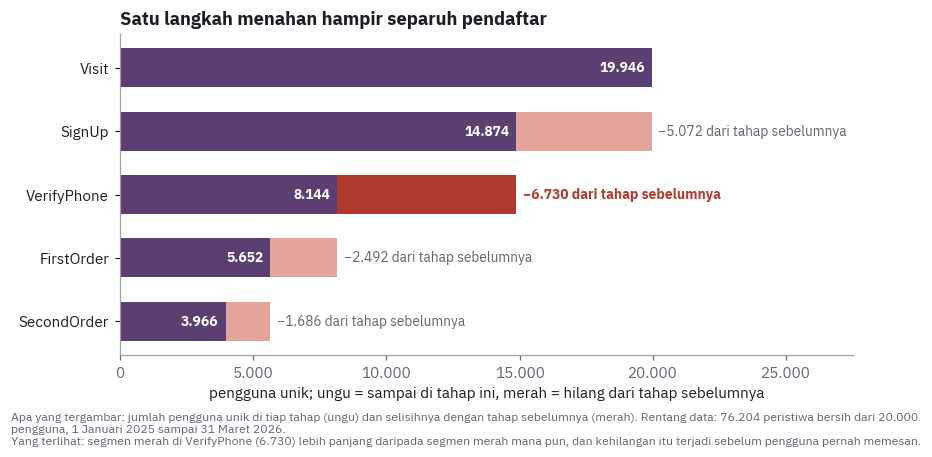

In [24]:
# Gambar 1 (temuan utama 1): cacah pengguna per tahap; bagian yang hilang dari tahap sebelumnya digambar merah
fig, ax = plt.subplots(figsize=(8.6, 3.8))
nama_tahap = list(funnel.EventName)
cacah = list(funnel.users)
for i, (t, v) in enumerate(zip(nama_tahap, cacah)):
    y = len(cacah) - 1 - i
    ax.barh(y, v, color=UNGU, height=0.62)
    ax.text(v - 250, y, angka_id(v), va="center", ha="right", fontsize=9, fontweight="bold", color="white")
    if i > 0:
        hilang = cacah[i - 1] - v
        warna_h = MERAH if t == "VerifyPhone" else MERAH_MUDA
        ax.barh(y, hilang, left=v, color=warna_h, height=0.62)
        ax.text(cacah[i - 1] + 250, y, f"−{angka_id(hilang)} dari tahap sebelumnya",
                va="center", fontsize=9, color=MERAH if t == "VerifyPhone" else ABU_TUA,
                fontweight="bold" if t == "VerifyPhone" else "normal")
ax.set_yticks(range(len(cacah)), nama_tahap[::-1])
ax.set_xlim(0, 27500); ax.xaxis.set_major_formatter(fmt_ribu)
ax.set_title("Satu langkah menahan hampir separuh pendaftar")
ax.set_xlabel("pengguna unik; ungu = sampai di tahap ini, merah = hilang dari tahap sebelumnya")
simpan(fig, "gambar1_cacah_per_tahap",
       "Apa yang tergambar: jumlah pengguna unik di tiap tahap (ungu) dan selisihnya dengan tahap sebelumnya (merah). Rentang data: " + RENTANG +
       ".\nYang terlihat: segmen merah di VerifyPhone (6.730) lebih panjang daripada segmen merah mana pun, dan kehilangan itu terjadi sebelum pengguna pernah memesan.")

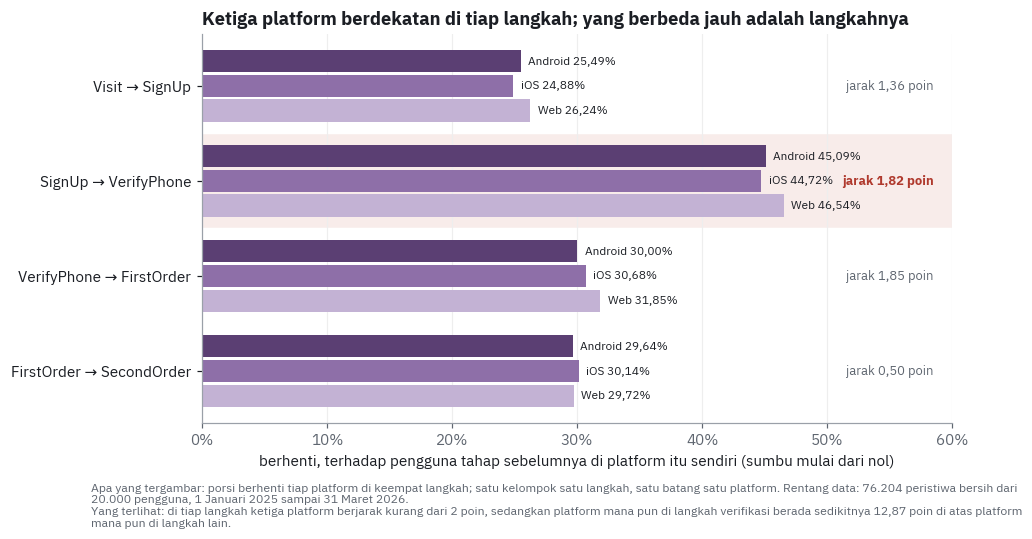

In [25]:
# Gambar 2 (temuan utama 2): porsi berhenti per platform di keempat langkah. Pertanyaannya: apakah selisih antarplatform
# sebanding dengan selisih antar-langkah? Platform dibedakan dengan tiga tingkat ungu;
# baris langkah verifikasi diberi latar merah muda karena di situlah kehilangan terbesar.
berhenti_pf = (100 - platform_konv).round(2)          # baris: platform, kolom: langkah
fig, ax = plt.subplots(figsize=(8.8, 4.6))
warna_pf = {"Android": UNGU, "iOS": "#8E6FA8", "Web": "#C3B2D4"}
baris_l = urut_langkah[::-1]
tinggi = 0.26
for yy, l in enumerate(baris_l):
    if l == "SignUp ke VerifyPhone":
        ax.axhspan(yy - 0.48, yy + 0.48, color="#F8ECEA", zorder=0)
    for k, (pf, warna) in enumerate(warna_pf.items()):
        v = berhenti_pf.loc[pf, l]
        yb = yy + (1 - k) * tinggi
        ax.barh(yb, v, height=tinggi * 0.9, color=warna, zorder=2)
        ax.text(v + 0.6, yb, f"{pf} {angka_id(v, 2)}%", va="center", fontsize=7.8, color=TEKS)
    lo, hi = berhenti_pf[l].min(), berhenti_pf[l].max()
    ax.text(58.5, yy, f"jarak {angka_id(hi - lo, 2)} poin", va="center", ha="right", fontsize=8.5,
            color=MERAH if l == "SignUp ke VerifyPhone" else ABU_TUA, fontweight="bold" if l == "SignUp ke VerifyPhone" else "normal")
ax.set_yticks(range(4), [l.replace(" ke ", " → ") for l in baris_l])
ax.set_xlim(0, 60); ax.xaxis.set_major_formatter(fmt_persen); ax.set_ylim(-0.55, 3.55)
ax.grid(axis="x", color="#EEEEEE"); ax.set_axisbelow(True)
ax.set_title("Ketiga platform berdekatan di tiap langkah; yang berbeda jauh adalah langkahnya")
ax.set_xlabel("berhenti, terhadap pengguna tahap sebelumnya di platform itu sendiri (sumbu mulai dari nol)")
lain_max = berhenti_pf.drop(columns="SignUp ke VerifyPhone").max().max()
jarak_klaster = berhenti_pf["SignUp ke VerifyPhone"].min() - lain_max
simpan(fig, "gambar2_platform_per_langkah",
       "Apa yang tergambar: porsi berhenti tiap platform di keempat langkah; satu kelompok satu langkah, satu batang satu platform. Rentang data: " + RENTANG +
       f".\nYang terlihat: di tiap langkah ketiga platform berjarak kurang dari 2 poin, sedangkan platform mana pun di langkah verifikasi berada sedikitnya {angka_id(jarak_klaster,2)} poin di atas platform mana pun di langkah lain.")

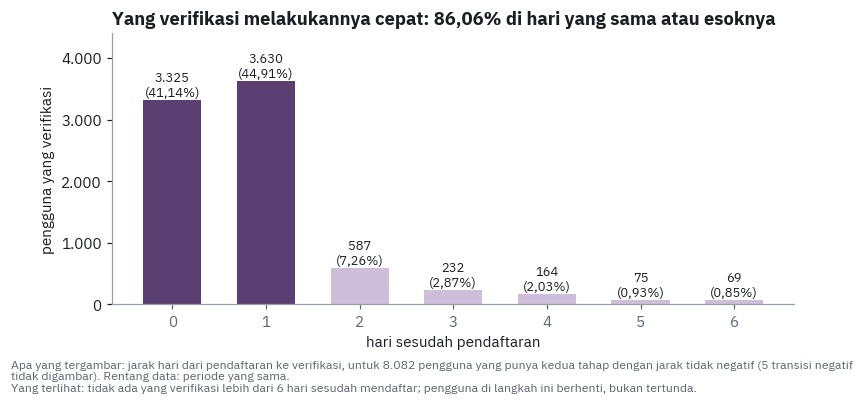

In [26]:
# Gambar 3 (temuan pendukung 1): kecepatan verifikasi di antara pendaftar yang verifikasi
fig, ax = plt.subplots(figsize=(8, 3.2))
sv7 = sebaran_sv[sebaran_sv.hari >= 0]
ax.bar(sv7.hari.astype(str), sv7.pengguna, color=[UNGU if h <= 1 else UNGU_MUDA for h in sv7.hari], width=0.62)
for i, (n, p) in enumerate(zip(sv7.pengguna, sv7.pengguna / sv7.pengguna.sum() * 100)):
    ax.text(i, n + 60, f"{angka_id(n)}\n({angka_id(p,2)}%)", ha="center", fontsize=8.5)
ax.set_ylim(0, 4400); ax.yaxis.set_major_formatter(fmt_ribu)
ax.set_xlabel("hari sesudah pendaftaran"); ax.set_ylabel("pengguna yang verifikasi")
dalam_1 = sv7[sv7.hari <= 1].pengguna.sum() / sv7.pengguna.sum() * 100
ax.set_title(f"Yang verifikasi melakukannya cepat: {angka_id(dalam_1,2)}% di hari yang sama atau esoknya")
simpan(fig, "gambar3_kecepatan_verifikasi",
       "Apa yang tergambar: jarak hari dari pendaftaran ke verifikasi, untuk 8.082 pengguna yang punya kedua tahap dengan jarak tidak negatif (5 transisi negatif tidak digambar). Rentang data: periode yang sama."
       "\nYang terlihat: tidak ada yang verifikasi lebih dari 6 hari sesudah mendaftar; pengguna di langkah ini berhenti, bukan tertunda.")

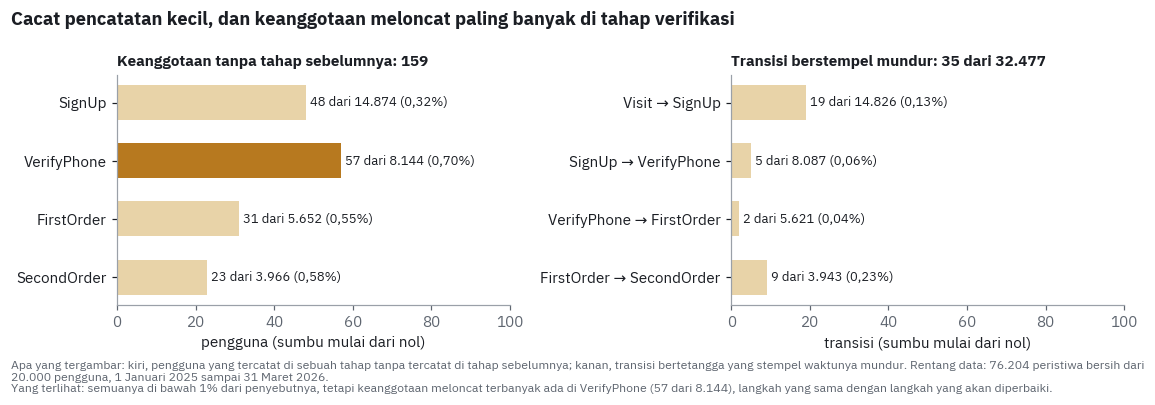

In [27]:
# Gambar 4 (temuan pendukung 2): cacat pencatatan. Kiri: keanggotaan tahap tanpa tahap sebelumnya, per tahap.
# Kanan: transisi bertetangga berstempel mundur, per langkah. Kuning tua karena ini penanda perhatian
# tentang alat ukur, bukan kehilangan pengguna.
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
ax = axs[0]
loncat = v5.copy()
loncat["porsi"] = loncat.tanpa_tahap_sebelumnya / loncat.pengguna_di_tahap * 100
yy = np.arange(len(loncat))[::-1]
tertinggi = loncat.tanpa_tahap_sebelumnya.idxmax()
ax.barh(yy, loncat.tanpa_tahap_sebelumnya, color=[KUNING if i == tertinggi else "#E8D3A8" for i in loncat.index], height=0.6)
for y_, (_, r) in zip(yy, loncat.iterrows()):
    ax.text(r.tanpa_tahap_sebelumnya + 1, y_, f"{int(r.tanpa_tahap_sebelumnya)} dari {angka_id(r.pengguna_di_tahap)} ({angka_id(r.porsi, 2)}%)",
            va="center", fontsize=8.5, color=TEKS)
ax.set_yticks(yy, loncat.EventName); ax.set_xlim(0, 100)
ax.set_title(f"Keanggotaan tanpa tahap sebelumnya: {int(loncat.tanpa_tahap_sebelumnya.sum())}", fontsize=10)
ax.set_xlabel("pengguna (sumbu mulai dari nol)")
ax = axs[1]
mundur = q("SELECT event_name || ' → ' || CASE stage_number WHEN 1 THEN 'SignUp' WHEN 2 THEN 'VerifyPhone' "
           "WHEN 3 THEN 'FirstOrder' ELSE 'SecondOrder' END AS langkah, "
           "COUNT(*) FILTER (WHERE days_to_next < 0) AS mundur, COUNT(*) AS transisi "
           "FROM gold.time_between WHERE next_stage = stage_number + 1 GROUP BY stage_number, event_name ORDER BY stage_number")
mundur["porsi"] = mundur.mundur / mundur.transisi * 100
yy = np.arange(len(mundur))[::-1]
ax.barh(yy, mundur.mundur, color="#E8D3A8", height=0.6)
for y_, (_, r) in zip(yy, mundur.iterrows()):
    ax.text(r.mundur + 1, y_, f"{int(r.mundur)} dari {angka_id(r.transisi)} ({angka_id(r.porsi, 2)}%)", va="center", fontsize=8.5, color=TEKS)
ax.set_yticks(yy, mundur.langkah); ax.set_xlim(0, 100)
ax.set_title(f"Transisi berstempel mundur: {int(mundur.mundur.sum())} dari {angka_id(mundur.transisi.sum())}", fontsize=10)
ax.set_xlabel("transisi (sumbu mulai dari nol)")
fig.suptitle("Cacat pencatatan kecil, dan keanggotaan meloncat paling banyak di tahap verifikasi", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan(fig, "gambar4_cacat_pencatatan",
       "Apa yang tergambar: kiri, pengguna yang tercatat di sebuah tahap tanpa tercatat di tahap sebelumnya; kanan, transisi bertetangga yang stempel waktunya mundur. Rentang data: " + RENTANG +
       ".\nYang terlihat: semuanya di bawah 1% dari penyebutnya, tetapi keanggotaan meloncat terbanyak ada di VerifyPhone (57 dari 8.144), langkah yang sama dengan langkah yang akan diperbaiki.")

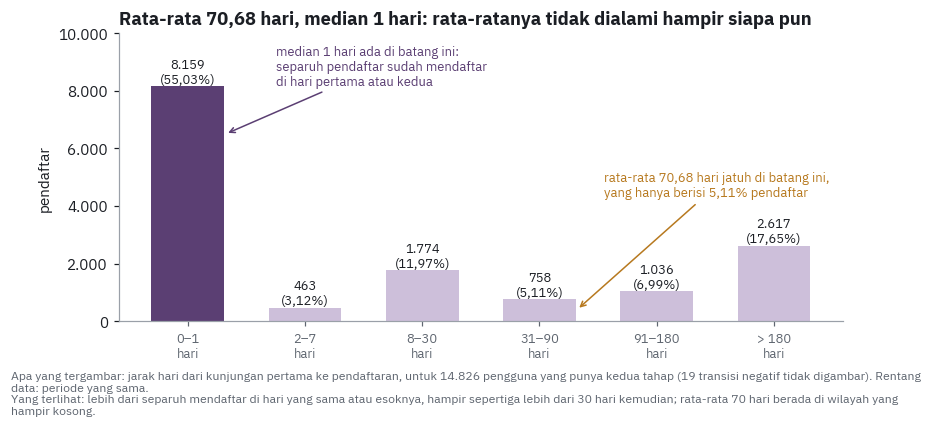

In [28]:
# Gambar 5 (temuan pendukung 3): sebaran jarak Visit ke SignUp; jarak waktu tidak punya arah baik-buruk, jadi ungu
fig, ax = plt.subplots(figsize=(8.5, 3.4))
sv = sebaran_vs[sebaran_vs.rentang != "a. negatif"]
lbl6 = [r[3:].replace(" sampai ", "–").replace("lebih dari ", "> ").replace(" hari", "\nhari") for r in sv.rentang]
ax.bar(lbl6, sv.pendaftar, color=[UNGU if i == 0 else UNGU_MUDA for i in range(len(sv))], width=0.62)
for i, (n, p) in enumerate(zip(sv.pendaftar, sv.porsi_persen)):
    ax.text(i, n + 120, f"{angka_id(n)}\n({angka_id(p,2)}%)", ha="center", fontsize=8.5)
ax.yaxis.set_major_formatter(fmt_ribu); ax.set_ylim(0, 10000)
ax.tick_params(axis="x", labelsize=8.5)
med, avg = waktu.median_hari[0], waktu.rata_rata_hari[0]
ax.annotate(f"median {angka_id(med,0)} hari ada di batang ini:\nseparuh pendaftar sudah mendaftar\ndi hari pertama atau kedua",
            xy=(0.32, 6500), xytext=(0.75, 9600), fontsize=8.5, color=UNGU, va="top",
            arrowprops=dict(arrowstyle="->", color=UNGU, lw=1))
ax.annotate(f"rata-rata {angka_id(avg,2)} hari jatuh di batang ini,\nyang hanya berisi 5,11% pendaftar",
            xy=(3.32, 400), xytext=(3.55, 5200), fontsize=8.5, color=KUNING, va="top",
            arrowprops=dict(arrowstyle="->", color=KUNING, lw=1))
ax.set_title(f"Rata-rata {angka_id(avg,2)} hari, median {angka_id(med,0)} hari: rata-ratanya tidak dialami hampir siapa pun")
ax.set_ylabel("pendaftar")
simpan(fig, "gambar5_jarak_kunjungan_pendaftaran",
       "Apa yang tergambar: jarak hari dari kunjungan pertama ke pendaftaran, untuk 14.826 pengguna yang punya kedua tahap (19 transisi negatif tidak digambar). Rentang data: periode yang sama."
       "\nYang terlihat: lebih dari separuh mendaftar di hari yang sama atau esoknya, hampir sepertiga lebih dari 30 hari kemudian; rata-rata 70 hari berada di wilayah yang hampir kosong.")

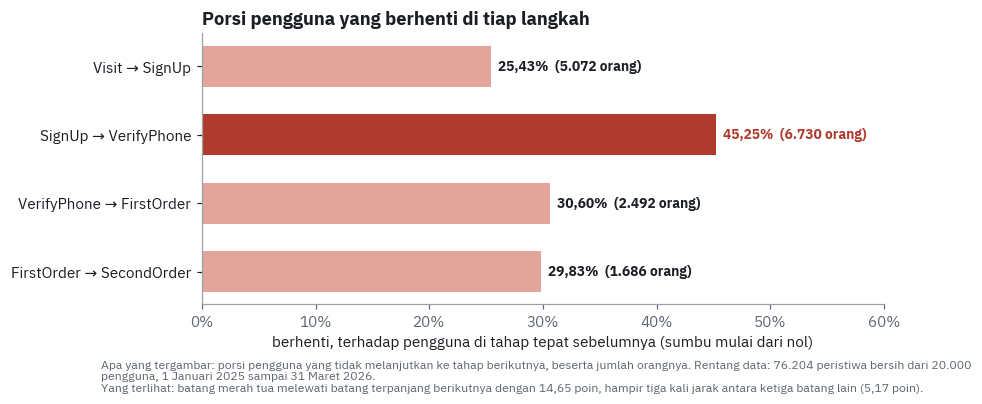

In [29]:
# Gambar 6 (pemeriksaan temuan utama 1): porsi berhenti di tiap langkah; semuanya kehilangan, jadi semuanya merah
fig, ax = plt.subplots(figsize=(8, 3.2))
val = langkah.drop_off_rate.values[::-1]
hilang = langkah.users_lost.values[::-1]
lbl = lbl_panah[::-1]
ax.barh(lbl, val, color=[MERAH if v == val.max() else MERAH_MUDA for v in val], height=0.6)
for y, (v, h) in enumerate(zip(val, hilang)):
    ax.text(v + 0.6, y, f"{angka_id(v,2)}%  ({angka_id(h)} orang)", va="center", fontsize=9,
            color=MERAH if v == val.max() else TEKS, fontweight="bold")
ax.set_xlim(0, 60); ax.xaxis.set_major_formatter(fmt_persen)
ax.set_title("Porsi pengguna yang berhenti di tiap langkah")
ax.set_xlabel("berhenti, terhadap pengguna di tahap tepat sebelumnya (sumbu mulai dari nol)")
simpan(fig, "gambar6_porsi_berhenti",
       "Apa yang tergambar: porsi pengguna yang tidak melanjutkan ke tahap berikutnya, beserta jumlah orangnya. Rentang data: " + RENTANG +
       ".\nYang terlihat: batang merah tua melewati batang terpanjang berikutnya dengan 14,65 poin, hampir tiga kali jarak antara ketiga batang lain (5,17 poin).")

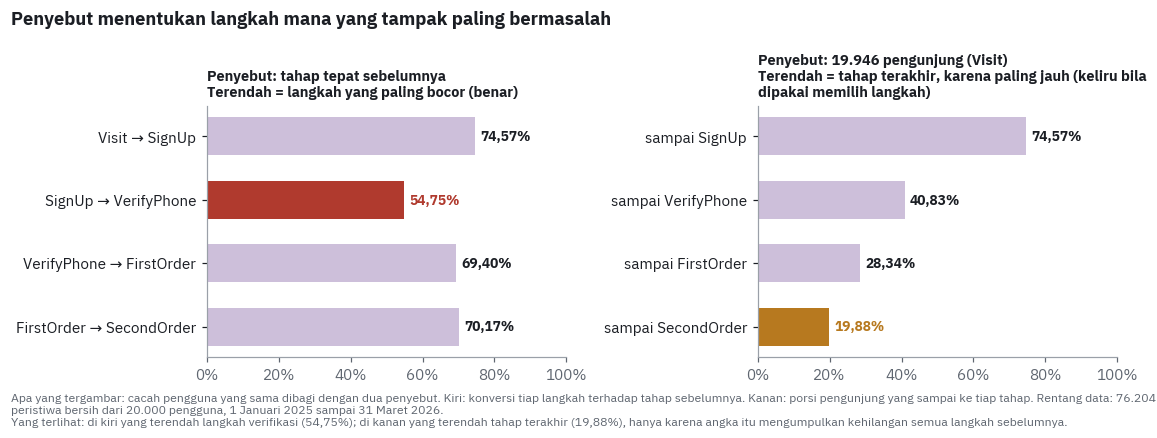

In [30]:
# Gambar 7 (pemeriksaan penyebut): cacah yang sama dibagi dengan dua penyebut berbeda.
# Kiri: konversi tiap langkah (penyebut = tahap tepat sebelumnya). Kanan: porsi pengunjung yang sampai ke tiap tahap
# (penyebut = Visit). Tiap panel diberi label sendiri, dan batang terendah di tiap panel disorot.
vs_prev = langkah.conversion_rate.values
vs_first = (funnel.users / funnel.users.iloc[0] * 100).values[1:]
lbl_kanan = ["sampai SignUp", "sampai VerifyPhone", "sampai FirstOrder", "sampai SecondOrder"]
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
y = np.arange(4)[::-1]
for ax, nilai, label, warna_rendah, judul in [
        (axs[0], vs_prev, lbl_panah, MERAH, "Penyebut: tahap tepat sebelumnya\nTerendah = langkah yang paling bocor (benar)"),
        (axs[1], vs_first, lbl_kanan, KUNING, "Penyebut: 19.946 pengunjung (Visit)\nTerendah = tahap terakhir, karena paling jauh (keliru bila\ndipakai memilih langkah)")]:
    rendah = int(np.argmin(nilai))
    ax.barh(y, nilai, color=[warna_rendah if k == rendah else UNGU_MUDA for k in range(4)], height=0.6)
    for yy, v, k in zip(y, nilai, range(4)):
        ax.text(v + 1.5, yy, angka_id(v, 2) + "%", va="center", fontsize=9, fontweight="bold",
                color=warna_rendah if k == rendah else TEKS)
    ax.set_yticks(y, label); ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(fmt_persen)
    ax.set_title(judul, fontsize=9.5)
fig.suptitle("Penyebut menentukan langkah mana yang tampak paling bermasalah", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan(fig, "gambar7_dua_penyebut",
       "Apa yang tergambar: cacah pengguna yang sama dibagi dengan dua penyebut. Kiri: konversi tiap langkah terhadap tahap sebelumnya. Kanan: porsi pengunjung yang sampai ke tiap tahap. Rentang data: " + RENTANG +
       ".\nYang terlihat: di kiri yang terendah langkah verifikasi (54,75%); di kanan yang terendah tahap terakhir (19,88%), hanya karena angka itu mengumpulkan kehilangan semua langkah sebelumnya.")

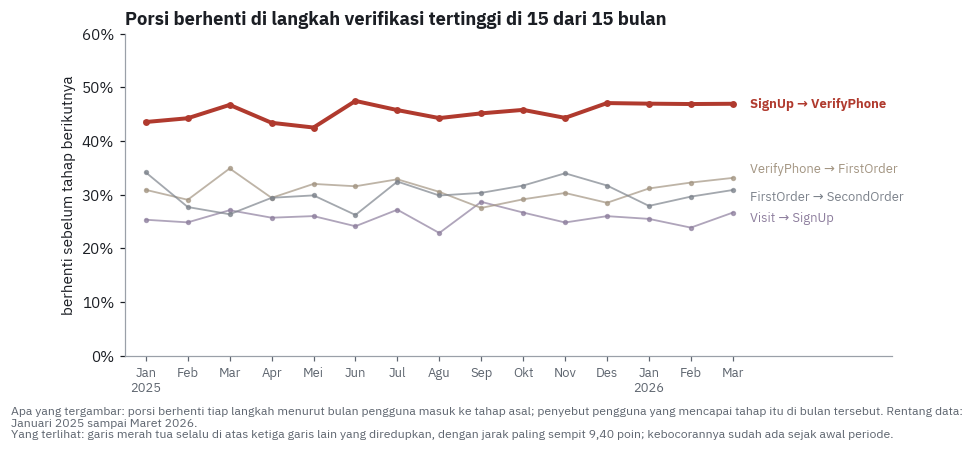

In [31]:
# Gambar 8 (pemeriksaan ketahanan): porsi berhenti tiap langkah per bulan masuk tahap
# Langkah verifikasi disorot merah tua; tiga langkah lain diberi warna redup yang berbeda supaya tetap bisa dibedakan
WARNA_LAIN = {"Visit ke SignUp": "#8E7F9E", "VerifyPhone ke FirstOrder": "#A39582", "FirstOrder ke SecondOrder": "#7D838C"}
kohort_berhenti = (100 - kohort_lebar[urut_langkah]).round(2)
fig, ax = plt.subplots(figsize=(9, 3.8))
bulan = kohort_berhenti.index
xb = np.arange(len(bulan))
geser = {"Visit ke SignUp": -1.0, "FirstOrder ke SecondOrder": -1.3, "VerifyPhone ke FirstOrder": 1.6, "SignUp ke VerifyPhone": 0}
for l in urut_langkah:
    is_v = l == "SignUp ke VerifyPhone"
    warna = MERAH if is_v else WARNA_LAIN[l]
    ax.plot(xb, kohort_berhenti[l], marker="o", ms=3.5 if is_v else 2.5, lw=2.6 if is_v else 1.2,
            color=warna, alpha=1 if is_v else 0.7, zorder=3 if is_v else 2)
    ax.text(len(bulan) - 0.6, kohort_berhenti[l].iloc[-1] + geser[l], l.replace(" ke ", " → "), va="center", fontsize=8.5,
            color=warna, fontweight="bold" if is_v else "normal")
nama_bulan = {"01":"Jan","02":"Feb","03":"Mar","04":"Apr","05":"Mei","06":"Jun","07":"Jul","08":"Agu","09":"Sep","10":"Okt","11":"Nov","12":"Des"}
ax.set_xticks(xb, [nama_bulan[b[5:]] + ("\n" + b[:4] if b[5:] == "01" else "") for b in bulan], fontsize=8.5)
ax.set_ylim(0, 60); ax.yaxis.set_major_formatter(fmt_persen); ax.set_xlim(-0.5, len(bulan) + 2.8)
ax.set_title("Porsi berhenti di langkah verifikasi tertinggi di 15 dari 15 bulan")
ax.set_ylabel("berhenti sebelum tahap berikutnya")
jarak_min_bulan = (kohort_berhenti["SignUp ke VerifyPhone"] - kohort_berhenti[urut_langkah].drop(columns="SignUp ke VerifyPhone").max(axis=1)).min()
simpan(fig, "gambar8_porsi_berhenti_bulanan",
       "Apa yang tergambar: porsi berhenti tiap langkah menurut bulan pengguna masuk ke tahap asal; penyebut pengguna yang mencapai tahap itu di bulan tersebut. Rentang data: Januari 2025 sampai Maret 2026."
       f"\nYang terlihat: garis merah tua selalu di atas ketiga garis lain yang diredupkan, dengan jarak paling sempit {angka_id(jarak_min_bulan,2)} poin; kebocorannya sudah ada sejak awal periode.")

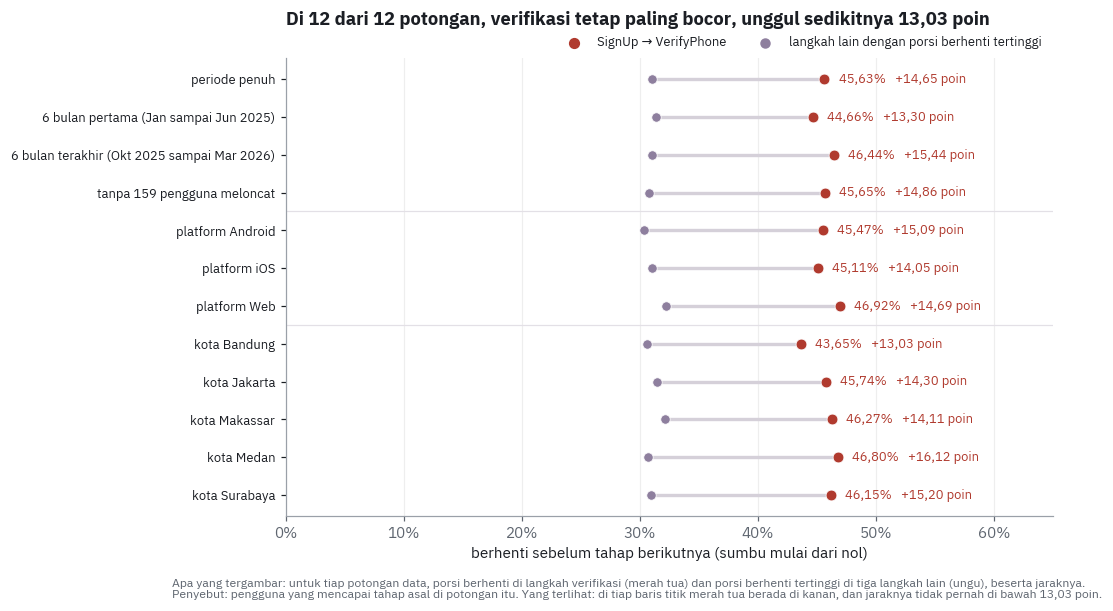

In [32]:
# Gambar 9 (pemeriksaan ketahanan): ketahanan. Untuk tiap potongan: porsi berhenti di verifikasi lawan porsi berhenti tertinggi di
# tiga langkah lain. Kalau temuan utama rapuh, kedua titik akan bertemu atau bertukar tempat di salah satu baris.
ringkas_berhenti = (100 - ringkas[urut_langkah]).round(2)
lain = ringkas_berhenti.drop(columns="SignUp ke VerifyPhone")
dumbbell = pd.DataFrame({"verifikasi": ringkas_berhenti["SignUp ke VerifyPhone"],
                         "lain_tertinggi": lain.max(axis=1),
                         "langkah_lain": lain.idxmax(axis=1)})
dumbbell["jarak"] = (dumbbell.verifikasi - dumbbell.lain_tertinggi).round(2)
fig, ax = plt.subplots(figsize=(9, 5.4))
baris = list(dumbbell.index)[::-1]
for yy, pot in enumerate(baris):
    r = dumbbell.loc[pot]
    ax.plot([r.lain_tertinggi, r.verifikasi], [yy, yy], color="#D5D0D9", lw=2.2, zorder=1)
    ax.scatter(r.lain_tertinggi, yy, color="#8E7F9E", s=38, zorder=2, edgecolor="white", lw=0.5)
    ax.scatter(r.verifikasi, yy, color=MERAH, s=50, zorder=3, edgecolor="white", lw=0.5)
    ax.text(r.verifikasi + 1.2, yy, f"{angka_id(r.verifikasi,2)}%   +{angka_id(r.jarak,2)} poin", va="center", fontsize=8.5, color=MERAH)
for batas in [4.5, 7.5]:          # pemisah kelompok: kota | platform | periode
    ax.axhline(batas, color="#E3E0E6", lw=0.8)
ax.set_yticks(range(len(baris)), baris, fontsize=8.5)
ax.set_xlim(0, 65); ax.xaxis.set_major_formatter(fmt_persen)
ax.scatter([], [], color=MERAH, s=40, label="SignUp → VerifyPhone")
ax.scatter([], [], color="#8E7F9E", s=34, label="langkah lain dengan porsi berhenti tertinggi")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.995), ncol=2, frameon=False, fontsize=8.5)
ax.grid(axis="x", color="#EEEEEE"); ax.set_axisbelow(True)
jarak_min_pot = dumbbell.jarak.min()
ax.set_title(f"Di 12 dari 12 potongan, verifikasi tetap paling bocor, unggul sedikitnya {angka_id(jarak_min_pot,2)} poin", pad=22)
ax.set_xlabel("berhenti sebelum tahap berikutnya (sumbu mulai dari nol)")
simpan(fig, "gambar9_ketahanan",
       "Apa yang tergambar: untuk tiap potongan data, porsi berhenti di langkah verifikasi (merah tua) dan porsi berhenti tertinggi di tiga langkah lain (ungu), beserta jaraknya."
       "\nPenyebut: pengguna yang mencapai tahap asal di potongan itu. Yang terlihat: di tiap baris titik merah tua berada di kanan, dan jaraknya tidak pernah di bawah "
       f"{angka_id(jarak_min_pot,2)} poin.")

## 9. Ekspor berkas dan gerbang angka

Notebook berhenti dengan galat kalau satu saja angka kunci meleset dari harapannya.

In [33]:
rekonsiliasi.to_csv(f"berkas/01_rekonsiliasi_pembersihan_{TANGGAL}.csv", index=False)
funnel.rename(columns={
    "EventName": "tahap", "users": "pengguna", "prev_users": "pengguna_tahap_sebelumnya",
    "conversion_rate": "konversi_thd_tahap_sebelumnya_persen", "drop_off_rate": "berhenti_thd_tahap_sebelumnya_persen",
    "users_lost": "pengguna_hilang", "porsi_dari_visit": "porsi_thd_visit_persen"}).to_csv(f"berkas/02_tabel_funnel_{TANGGAL}.csv", index=False)
pecahan.rename(columns={"konversi_thd_tahap_sebelumnya": "konversi_thd_tahap_sebelumnya_kelompok_itu_persen"}) \
    .to_csv(f"berkas/03_pecahan_platform_kota_{TANGGAL}.csv", index=False)
hasil_validasi.to_csv(f"berkas/04_hasil_validasi_{TANGGAL}.csv", index=False)
sorted(os.listdir("berkas"))

['01_rekonsiliasi_pembersihan_2026-10-08.csv',
 '02_tabel_funnel_2026-10-08.csv',
 '03_pecahan_platform_kota_2026-10-08.csv',
 '04_hasil_validasi_2026-10-08.csv']

In [34]:
gerbang = {
    "baris mentah": (n0, 80000), "sesudah kembar": (n1, 76850), "sesudah nama kosong": (n2, 76350), "baris bersih": (n3, 76204),
    "keanggotaan": (int(silver.keanggotaan[0]), 52582),
    "cacah lima tahap": (tuple(funnel.users), (19946, 14874, 8144, 5652, 3966)),
    "berhenti di verifikasi": (int(terburuk.users_lost), 6730), "pendaftar tak pernah verifikasi": (tv, 6787),
    "porsi berhenti verifikasi": (terburuk.drop_off_rate, 45.25),
    "jarak platform verifikasi": (jarak_platform["SignUp ke VerifyPhone"], 1.82),
    "keanggotaan meloncat": (int(v5.tanpa_tahap_sebelumnya.sum()), 159),
    "transisi mundur": ((int(v3.transisi_mundur[0]), int(v3.transisi_diperiksa[0])), (35, 32477)),
    "verifikasi terendah per bulan": (int(kohort_lebar.verifikasi_terendah.sum()), 15),
    "verifikasi terendah per potongan": (int((ringkas.langkah_terendah == "SignUp ke VerifyPhone").sum()), 12),
}
for nama, (hasil, harapan) in gerbang.items():
    assert hasil == harapan, f"Gerbang gagal: {nama}: {hasil} != {harapan}"
print(f"Seluruh {len(gerbang)} gerbang angka lolos.")

Seluruh 14 gerbang angka lolos.


## 10. Temuan dan rekomendasi

Data ini menunjukkan **di mana** orang berhenti, bukan **kenapa**: tidak ada percobaan, catatan pengiriman kode, maupun alasan berhenti.

Temuan dipisah dua. Temuan utama menentukan ke mana satu antrean kerja diarahkan. Temuan pendukung menentukan cara menjalankan rekomendasinya dan batas klaim yang boleh dibuat.

### Temuan utama

**Utama 1. Satu langkah menahan 6.730 dari 14.874 pendaftar.** Konversi SignUp ke VerifyPhone 54,75%, artinya <strong>45,25% pendaftar berhenti di situ</strong>. Porsi yang berhenti di tiga langkah lain 25,43%, 30,60%, dan 29,83%, jadi langkah verifikasi bukan sekadar yang terburuk, melainkan terburuk dengan jarak lebar. Dalam satuan orang, langkah ini <strong>kehilangan lebih banyak daripada dua langkah terakhir digabung</strong> (6.730 lawan 4.178). Porsi berhentinya <strong>tertinggi di 15 dari 15 bulan dan di 12 dari 12 potongan data</strong>. (Gambar 1)

**Utama 2. Selisih antarplatform terlalu kecil untuk jadi dasar prioritas.** Perbedaannya nyata dan arahnya konsisten: di langkah verifikasi Web 53,46%, Android 54,91%, iOS 55,28%, dan Web terendah di tiga dari empat langkah. Tetapi <strong>jarak terlebarnya 1,82 poin, tidak bisa dibedakan dari kebetulan</strong> (p = 0,27), dan di langkah mana pun jarak antarplatform tidak mencapai 2 poin. Platform mana pun di langkah verifikasi berada sedikitnya 12,87 poin di atas platform mana pun di langkah lain: <strong>yang membedakan adalah langkahnya, bukan platformnya</strong>. Kota menunjukkan pola yang sama: 53,51% sampai 56,69%, p = 0,17. Yang tidak diklaim: bahwa platform tidak berpengaruh. (Gambar 2)

### Temuan pendukung

**Pendukung 1. Di langkah verifikasi, orang berhenti, bukan tertunda.** <strong>86,06%</strong> dari pendaftar yang verifikasi melakukannya di hari daftar atau esoknya, dan <strong>tidak satu pun lebih dari 6 hari</strong> kemudian. Akibatnya, <strong>uji perbaikan di langkah ini cukup dibaca 7 hari sesudah tiap pendaftaran</strong>. (Gambar 3)

**Pendukung 2. Alat ukurnya belum sepenuhnya bisa dipercaya.** 159 keanggotaan tahap muncul tanpa tahap sebelumnya, dan 35 dari 32.477 transisi bertetangga berstempel waktu mundur (0,11%). Tanpa ke-159 pengguna itu langkah verifikasi tetap terburuk (45,65% berhenti), jadi <strong>temuan utama tidak berubah</strong>. Tetapi angka funnel punya batas ketelitian, dan <strong>pencatatan perlu diaudit sebelum hasil uji dibaca</strong>, dimulai dari VerifyPhone: di tahap itulah keanggotaan meloncat paling banyak (57 dari 8.144). (Gambar 4)

**Pendukung 3. Rata-rata jarak kunjungan ke pendaftaran menyesatkan kalau berdiri sendiri.** Rata-rata Visit ke SignUp 70,68 hari, tetapi <strong>mediannya 1 hari</strong>: 55,03% mendaftar di hari yang sama atau esoknya, dan 29,75% lebih dari 30 hari kemudian. Angka rata-rata itu <strong>tidak dialami hampir siapa pun</strong>, jadi tidak dilaporkan sendirian. (Gambar 5)

### Rekomendasi

- **Mendesak:** satu antrean kerja kuartal ini untuk langkah verifikasi telepon, ketiga platform sekaligus, sebagai uji dengan kelompok pembanding.
- **Dahulukan:** audit kelengkapan pencatatan peristiwa verifikasi sebelum hasil uji dibaca, dimulai dari VerifyPhone.
- **Jangan:** memprioritaskan satu platform, termasuk Web; selisihnya 1,82 poin.
- **Jangan:** menjanjikan kenaikan lima poin; data tidak memuat satu pun percobaan.
- **Periksa:** perubahan alur verifikasi di akhir 2025 (bukti lemah, p 0,04).

**Ukuran pembatal**, ditetapkan sebelum perbaikan dikerjakan: konversi pendaftaran ke verifikasi kelompok uji lawan pembanding, dibaca 7 hari sesudah tiap pendaftaran; jumlah pendaftar yang menyelesaikan verifikasi, dalam satuan orang (8.144 dari 14.874); dan cacah keanggotaan meloncat (159).